# Convergence of the finite element error

This tutorial follows the chapter on error control and convergence in the
[FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/).
We solve a Poisson problem with a smooth manufactured solution on a sequence of
uniformly refined meshes, for polynomial degrees $k = 1, \dots, 4$, and measure the
error in the $L^2$ and $H^1$ norms.  For a smooth solution the theory predicts

$$ \|u - u_h\|_{L^2} = O(h^{k+1}), \qquad \|u - u_h\|_{H^1} = O(h^{k}) . $$

The problem is $-\Delta u = f$ on the unit square with $u_e = \sin(2\pi x)\cos(\pi y)$,
$f = 5\pi^2 u_e$, and $u = u_e$ on the boundary.

In [1]:
from ngsufl import *
import numpy as np


def solve_poisson(n, k):
    mesh = UnitSquareMesh(n, n)
    V = FunctionSpace(mesh, "Lagrange", k)
    x = SpatialCoordinate(mesh)
    u_e = sin(2 * pi * x[0]) * cos(pi * x[1])
    f = 5 * pi**2 * u_e
    u, v = TrialFunction(V), TestFunction(V)
    uh = Function(V)
    solve(inner(grad(u), grad(v)) * dx == f * v * dx, uh, DirichletBC(V, u_e, "on_boundary"))
    return errornorm(u_e, uh), errornorm(u_e, uh, "H1"), V.dim()

## Error table

For each degree we halve the mesh size four times (from $2\times 2$ to $32\times 32$
cells) and compute the observed rate $\log_2(e_{h}/e_{h/2})$.

In [2]:
ns = [2, 4, 8, 16, 32]
results = {}
for k in range(1, 5):
    results[k] = [solve_poisson(n, k) for n in ns]

for k in range(1, 5):
    e = np.array([r[:2] for r in results[k]])
    rates = np.log2(e[:-1] / e[1:])
    print(f"degree {k}")
    print("    n    dofs     L2 error  rate     H1 error  rate")
    for i, n in enumerate(ns):
        rl = f"{rates[i - 1, 0]:5.2f}" if i else "    -"
        rh = f"{rates[i - 1, 1]:5.2f}" if i else "    -"
        print(f"{n:5d} {results[k][i][2]:7d}  {e[i, 0]:11.3e} {rl}  {e[i, 1]:11.3e} {rh}")

degree 1
    n    dofs     L2 error  rate     H1 error  rate
    2       9    4.308e-01     -    3.315e+00     -
    4      25    1.311e-01  1.72    1.976e+00  0.75
    8      81    3.704e-02  1.82    1.016e+00  0.96
   16     289    9.596e-03  1.95    5.106e-01  0.99
   32    1089    2.422e-03  1.99    2.556e-01  1.00
degree 2
    n    dofs     L2 error  rate     H1 error  rate
    2      25    9.813e-02     -    1.567e+00     -
    4      81    1.503e-02  2.71    4.540e-01  1.79
    8     289    2.013e-03  2.90    1.200e-01  1.92
   16    1089    2.590e-04  2.96    3.051e-02  1.98
   32    4225    3.266e-05  2.99    7.662e-03  1.99
degree 3
    n    dofs     L2 error  rate     H1 error  rate
    2      49    2.720e-02     -    5.265e-01     -
    4     169    1.870e-03  3.86    7.337e-02  2.84
    8     625    1.156e-04  4.02    9.362e-03  2.97
   16    2401    7.099e-06  4.03    1.172e-03  3.00
   32    9409    4.401e-07  4.01    1.465e-04  3.00
degree 4
    n    dofs     L2 error  

## Plot

In the log-log plot the errors lie on straight lines whose slope is the rate.  Dashed
lines, shifted down for readability, show the predicted slopes $k+1$ and $k$.

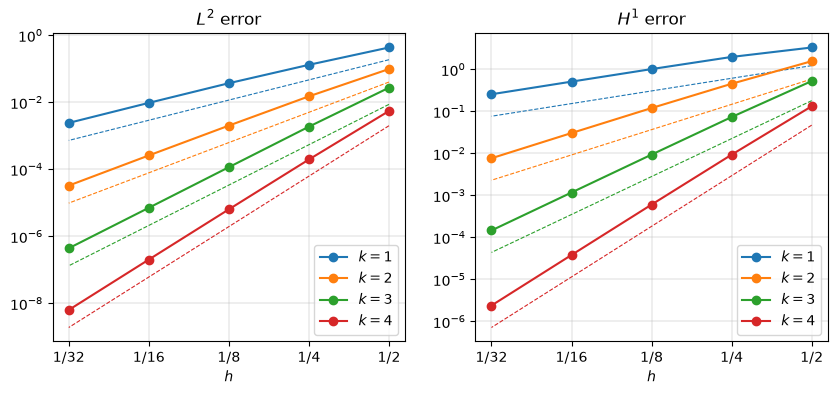

In [3]:
import matplotlib.pyplot as plt

h = 1.0 / np.array(ns)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for j, (name, ax) in enumerate(zip(["$L^2$ error", "$H^1$ error"], axes)):
    for k in range(1, 5):
        e = np.array([r[j] for r in results[k]])
        line, = ax.loglog(h, e, "o-", label=f"$k = {k}$")
        p = k + 1 - j
        ax.loglog(h, 0.3 * e[-1] * (h / h[-1])**p, "--", color=line.get_color(), lw=0.8)
    ax.set_xticks(h)
    ax.set_xticklabels([f"1/{n}" for n in ns])
    ax.minorticks_off()
    ax.set_xlabel("$h$")
    ax.set_title(name)
    ax.legend()
    ax.grid(True, which="both", lw=0.3)

## Quantitative check

The observed rates on the two finest meshes should be close to the predicted ones.

In [4]:
for k in range(1, 5):
    e = np.array([r[:2] for r in results[k]])
    r = np.log2(e[-2] / e[-1])
    print(f"k = {k}: L2 rate {r[0]:.2f} (expected {k + 1}), H1 rate {r[1]:.2f} (expected {k})")
    assert abs(r[0] - (k + 1)) < 0.3 and abs(r[1] - k) < 0.3

k = 1: L2 rate 1.99 (expected 2), H1 rate 1.00 (expected 1)
k = 2: L2 rate 2.99 (expected 3), H1 rate 1.99 (expected 2)
k = 3: L2 rate 4.01 (expected 4), H1 rate 3.00 (expected 3)
k = 4: L2 rate 4.99 (expected 5), H1 rate 4.00 (expected 4)


## High order is not more work

Going from $k = 1$ to $k = 4$ required no change other than the number in
`FunctionSpace`.  NGSolve's elements are hierarchical: the basis of degree $k$ contains
the basis of degree $k-1$, and the higher shape functions are built from orthogonal
polynomials on edges, faces and cells.  Arbitrary degrees are therefore available
without a separate element implementation.  Higher degree also pays off in cost: degree 4
on the $4\times4$ mesh uses fewer unknowns and is more accurate than degree 1 on the
$32\times 32$ mesh.

In [5]:
print("k=4, n=4 :", results[4][1][2], "dofs, L2 error", f"{results[4][1][0]:.2e}")
print("k=1, n=32:", results[1][4][2], "dofs, L2 error", f"{results[1][4][0]:.2e}")

k=4, n=4 : 289 dofs, L2 error 1.96e-04
k=1, n=32: 1089 dofs, L2 error 2.42e-03
